## 1. Setup

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch import optim
from torch.optim import SGD, Adam
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Settings


In [3]:
batch_size_no = 32
learning_rate = 1e-3
epoch_number = 20
IMG_SIZE = 128        

## 3. Load the mango dataset


In [4]:
MANUAL_PATH = '/kaggle/input/datasets/mdsiyamtalukder/mld-bd-primary/Main image File'     # example: "/kaggle/input/mango-leaf/Main image file"

def find_class_folder(root):
    # a folder that has 5 sub-folders (the classes), each containing images
    for current, subdirs, _ in os.walk(root):
        if len(subdirs) == 5:
            all_have_images = True
            for s in subdirs:
                files = os.listdir(os.path.join(current, s))
                if not any(f.lower().endswith((".jpg", ".jpeg", ".png")) for f in files):
                    all_have_images = False
            if all_have_images:
                return current
    return None

if MANUAL_PATH:
    data_dir = MANUAL_PATH
else:
    data_dir = None
    for root in ["/kaggle/input", "/content", "."]:
        if os.path.exists(root):
            data_dir = find_class_folder(root)
            if data_dir:
                break

print("Dataset folder:", data_dir)
for c in sorted(os.listdir(data_dir)):
    print(f"{c:20s} {len(os.listdir(os.path.join(data_dir, c)))} images")

Dataset folder: /kaggle/input/datasets/mdsiyamtalukder/mld-bd-primary/Main image File
Anthracnose          600 images
Bacterial_Canker     600 images
Die_Back             600 images
Gall_Mid             600 images
healthy              600 images


## 3. Split the data: train / validation

Our dataset has only the 5 class folders, so we make the split ourselves:

- **Training set (80%)**
- **Validation set (20%)**


In [9]:
class_names = sorted(os.listdir(data_dir))
print(class_names)

images, targets = [], []
for label, cls in enumerate(class_names):
    folder = os.path.join(data_dir, cls)
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            img = Image.open(os.path.join(folder, fname)).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img))
            targets.append(label)

images = np.array(images)       # shape: (N, 128, 128, 3)
targets = np.array(targets)     # shape: (N,)
print("All images:", images.shape)

# 80% train, 20% validation
tr_images, val_images, tr_targets, val_targets = train_test_split(
    images, targets, test_size=0.20, stratify=targets, random_state=0)

print("Train      :", tr_images.shape, " per class:", np.bincount(tr_targets).tolist())
print("Validation :", val_images.shape, " per class:", np.bincount(val_targets).tolist())

['Anthracnose', 'Bacterial_Canker', 'Die_Back', 'Gall_Mid', 'healthy']
All images: (3000, 128, 128, 3)
Train      : (2400, 128, 128, 3)  per class: [480, 480, 480, 480, 480]
Validation : (600, 128, 128, 3)  per class: [120, 120, 120, 120, 120]


### Look at a few images

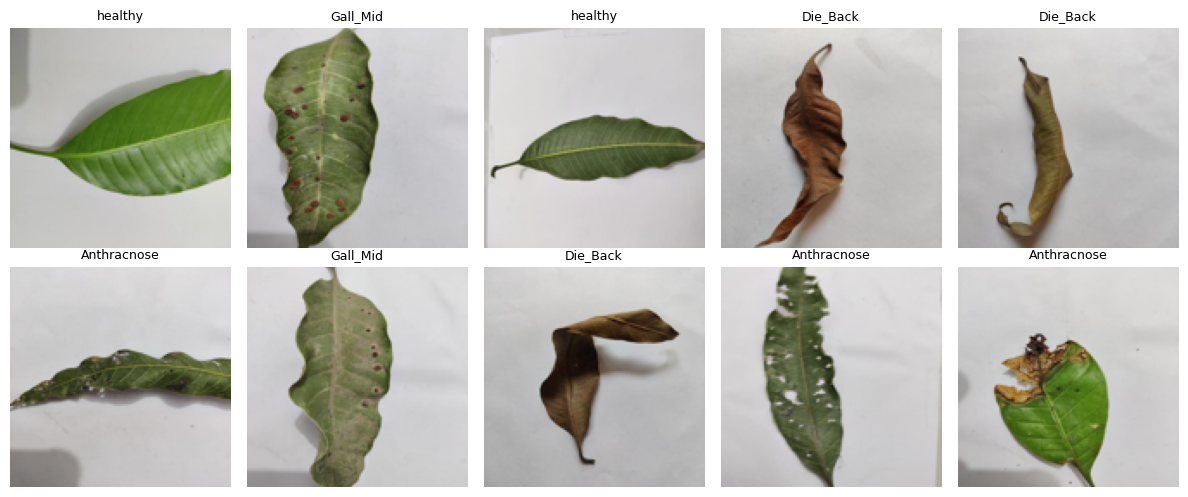

In [10]:
# Look at some images before training
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(tr_images[i * 200])
    plt.title(class_names[tr_targets[i * 200]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Dataset class and DataLoaders

In [12]:
class MangoDataset(Dataset):
    def __init__(self, x, y):
        x = torch.tensor(x)
        x = x.float() / 255           # Normalization
        x = x.permute(0, 3, 1, 2)     # N,Height,Width,Channel -> N,Channel,Height,Width

        y = torch.tensor(y)
        self.x, self.y = x, y

    def __getitem__(self, ix):
        x, y = self.x[ix], self.y[ix]
        return x.to(device), y.to(device)

    def __len__(self):
        return len(self.x)


def get_data():
    train = MangoDataset(tr_images, tr_targets)
    trn_dl = DataLoader(train, batch_size=batch_size_no, shuffle=True)
    val = MangoDataset(val_images, val_targets)
    val_dl = DataLoader(val, batch_size=batch_size_no, shuffle=False)
    return trn_dl, val_dl

## 5. The CNN Model

In [13]:
def get_model():
    model = nn.Sequential(

        # 1st Convolution
        nn.Conv2d(3, 40, 3, padding=1),    # 128x128
        nn.ReLU(),                         # 128x128
        nn.MaxPool2d(2),                   # 64x64

        # 2nd Convolution
        nn.Conv2d(40, 60, 3, padding=1),   # 64x64
        nn.ReLU(),                         # 64x64
        nn.MaxPool2d(2),                   # 32x32

        # 3rd Convolution
        nn.Conv2d(60, 80, 3, padding=1),   # 32x32
        nn.ReLU(),                         # 32x32
        nn.MaxPool2d(2),                   # 16x16

        # Classifier
        nn.Flatten(),
        nn.Linear(80*16*16, 256),
        nn.ReLU(),
        nn.Linear(256, 5)                  # 5 classes
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

## 6. Training and validation functions

In [15]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

## 7. Data and model summary

In [16]:
trn_dl, val_dl = get_data()
model, loss_fn, optimizer = get_model()

print("Train images     :", len(trn_dl.dataset))
print("Validation images:", len(val_dl.dataset))

try:
    from torchsummary import summary
    summary(model, input_size=(3, IMG_SIZE, IMG_SIZE), device=device)
except Exception:
    print(model)      # torchsummary is not installed, so print the model instead
    print("Total parameters:", sum(p.numel() for p in model.parameters()))

Train images     : 2400
Validation images: 600
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 40, 128, 128]           1,120
              ReLU-2         [-1, 40, 128, 128]               0
         MaxPool2d-3           [-1, 40, 64, 64]               0
            Conv2d-4           [-1, 60, 64, 64]          21,660
              ReLU-5           [-1, 60, 64, 64]               0
         MaxPool2d-6           [-1, 60, 32, 32]               0
            Conv2d-7           [-1, 80, 32, 32]          43,280
              ReLU-8           [-1, 80, 32, 32]               0
         MaxPool2d-9           [-1, 80, 16, 16]               0
          Flatten-10                [-1, 20480]               0
           Linear-11                  [-1, 256]       5,243,136
             ReLU-12                  [-1, 256]               0
           Linear-13                    [-1, 5]         

## 8. Training loop 

In [25]:
results = []          # one row per experiment (for the final table)
histories = {}        # loss / accuracy curves of every experiment
trained_models = {}   # the trained models


def run_experiment(name, get_model_function):
    print("=" * 75)
    print(name)
    print("=" * 75)
    torch.manual_seed(0)
    model, loss_fn, optimizer = get_model_function()

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                     factor=0.5, patience=0,
                                                     threshold=0.001,
                                                     min_lr=1e-5,
                                                     threshold_mode='abs')

    ### Training Loop ###
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []
    start = time.time()

    for epoch in range(epoch_number):
        epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        v_loss, v_acc = validation(val_dl, model, loss_fn)
        val_losses.append(v_loss)
        val_accuracies.append(v_acc)

        scheduler.step(v_loss)       # lower the learning rate if validation loss stops improving

        print(f"Epoch [{epoch + 1}/{epoch_number}]"
              f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
              f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

    # save everything for later
    histories[name] = {"train_losses": train_losses, "train_accuracies": train_accuracies,
                       "val_losses": val_losses, "val_accuracies": val_accuracies}
    trained_models[name] = model
    results.append({
        "Experiment": name,
        "Parameters": sum(p.numel() for p in model.parameters()),
        "Train acc": train_accuracies[-1],
        "Val acc": val_accuracies[-1],
        "Gap (train - val)": train_accuracies[-1] - val_accuracies[-1],
        "Time (s)": round(time.time() - start),
    })
    return model


def plot_curves(name):
    h = histories[name]
    epochs = np.arange(epoch_number) + 1
    plt.figure(figsize=(15, 3))
    plt.subplot(121)
    plt.title("Loss value over increasing epochs - " + name)
    plt.plot(epochs, h["train_losses"], marker='o', label="Training Loss")
    plt.plot(epochs, h["val_losses"], marker='o', label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(122)
    plt.title("Accuracy over Epochs - " + name)
    plt.plot(epochs, h["train_accuracies"], marker='o', label="Training Accuracy")
    plt.plot(epochs, h["val_accuracies"], marker='o', label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

## 9. Experiments

##  E0

E0: baseline
Epoch [1/20] | Train Loss: 1.3407 | Train Accuracy: 42.83% | Val Loss: 0.8578 | Val Accuracy: 64.00%
Epoch [2/20] | Train Loss: 0.7661 | Train Accuracy: 69.96% | Val Loss: 0.6650 | Val Accuracy: 76.17%
Epoch [3/20] | Train Loss: 0.5388 | Train Accuracy: 81.12% | Val Loss: 0.6559 | Val Accuracy: 74.83%
Epoch [4/20] | Train Loss: 0.4671 | Train Accuracy: 82.42% | Val Loss: 0.5053 | Val Accuracy: 84.00%
Epoch [5/20] | Train Loss: 0.3905 | Train Accuracy: 85.75% | Val Loss: 0.4737 | Val Accuracy: 83.00%
Epoch [6/20] | Train Loss: 0.2835 | Train Accuracy: 89.62% | Val Loss: 0.6274 | Val Accuracy: 81.00%
Epoch [7/20] | Train Loss: 0.2281 | Train Accuracy: 91.83% | Val Loss: 0.4978 | Val Accuracy: 82.33%
Epoch [8/20] | Train Loss: 0.1472 | Train Accuracy: 95.12% | Val Loss: 0.4147 | Val Accuracy: 85.83%
Epoch [9/20] | Train Loss: 0.1178 | Train Accuracy: 96.04% | Val Loss: 0.4253 | Val Accuracy: 86.00%
Epoch [10/20] | Train Loss: 0.0905 | Train Accuracy: 97.33% | Val Loss: 0.4246

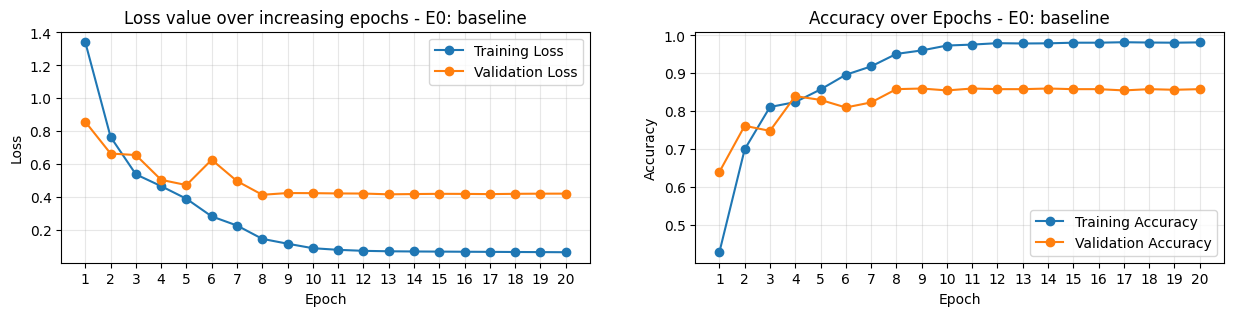

In [22]:
model_E0 = run_experiment("E0: baseline", get_model)
plot_curves("E0: baseline")

##  E1

E1: 2 conv layers
Epoch [1/20] | Train Loss: 1.7238 | Train Accuracy: 22.92% | Val Loss: 1.3489 | Val Accuracy: 43.33%
Epoch [2/20] | Train Loss: 0.9657 | Train Accuracy: 62.79% | Val Loss: 0.7126 | Val Accuracy: 74.83%
Epoch [3/20] | Train Loss: 0.6643 | Train Accuracy: 75.75% | Val Loss: 0.6940 | Val Accuracy: 74.50%
Epoch [4/20] | Train Loss: 0.5184 | Train Accuracy: 81.12% | Val Loss: 0.6646 | Val Accuracy: 78.00%
Epoch [5/20] | Train Loss: 0.4728 | Train Accuracy: 83.46% | Val Loss: 0.6168 | Val Accuracy: 79.17%
Epoch [6/20] | Train Loss: 0.2768 | Train Accuracy: 90.79% | Val Loss: 0.6397 | Val Accuracy: 77.00%
Epoch [7/20] | Train Loss: 0.1512 | Train Accuracy: 95.38% | Val Loss: 0.5963 | Val Accuracy: 80.67%
Epoch [8/20] | Train Loss: 0.0909 | Train Accuracy: 97.71% | Val Loss: 0.6097 | Val Accuracy: 80.50%
Epoch [9/20] | Train Loss: 0.0475 | Train Accuracy: 99.38% | Val Loss: 0.6388 | Val Accuracy: 79.83%
Epoch [10/20] | Train Loss: 0.0326 | Train Accuracy: 99.71% | Val Loss: 0

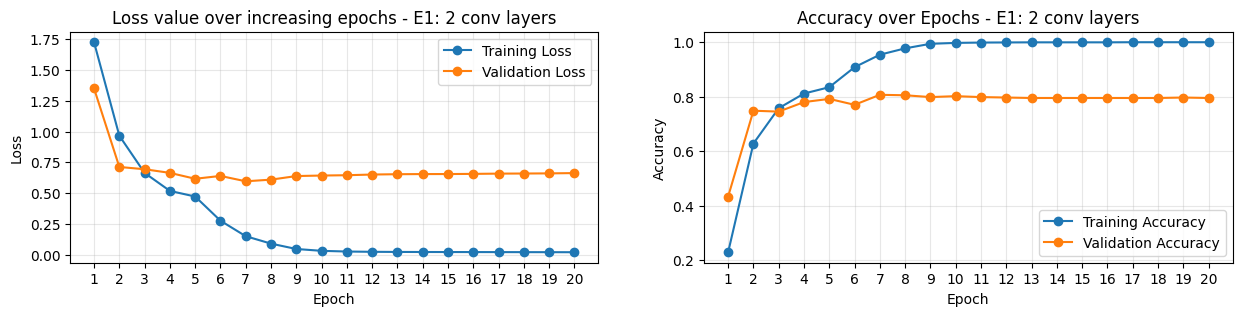

In [27]:
# E1: only 2 conv layers (3rd conv removed) -> after 2 pools the image is 32x32
def get_model_E1():
    model = nn.Sequential(
        nn.Conv2d(3, 40, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(40, 60, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Flatten(),
        nn.Linear(60*32*32, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E1 = run_experiment("E1: 2 conv layers", get_model_E1)
plot_curves("E1: 2 conv layers")

##  E2

E2: 4 conv layers
Epoch [1/20] | Train Loss: 1.5012 | Train Accuracy: 31.87% | Val Loss: 1.2593 | Val Accuracy: 49.50%
Epoch [2/20] | Train Loss: 0.9850 | Train Accuracy: 62.25% | Val Loss: 0.7465 | Val Accuracy: 74.83%
Epoch [3/20] | Train Loss: 0.6304 | Train Accuracy: 76.67% | Val Loss: 0.5955 | Val Accuracy: 80.00%
Epoch [4/20] | Train Loss: 0.5147 | Train Accuracy: 82.04% | Val Loss: 0.5314 | Val Accuracy: 81.67%
Epoch [5/20] | Train Loss: 0.4204 | Train Accuracy: 85.29% | Val Loss: 0.4852 | Val Accuracy: 83.83%
Epoch [6/20] | Train Loss: 0.3527 | Train Accuracy: 87.04% | Val Loss: 0.4410 | Val Accuracy: 83.00%
Epoch [7/20] | Train Loss: 0.3011 | Train Accuracy: 88.42% | Val Loss: 0.4352 | Val Accuracy: 82.50%
Epoch [8/20] | Train Loss: 0.2443 | Train Accuracy: 90.75% | Val Loss: 0.4202 | Val Accuracy: 86.33%
Epoch [9/20] | Train Loss: 0.2066 | Train Accuracy: 92.25% | Val Loss: 0.4097 | Val Accuracy: 87.50%
Epoch [10/20] | Train Loss: 0.2045 | Train Accuracy: 92.21% | Val Loss: 0

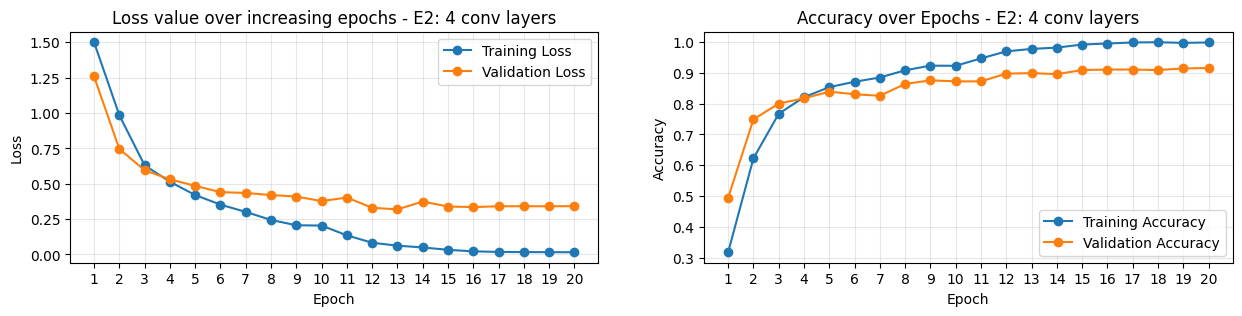

In [28]:
# E2: 4 conv layers (4th conv with 100 channels added) -> after 4 pools the image is 8x8
def get_model_E2():
    model = nn.Sequential(
        nn.Conv2d(3, 40, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(40, 60, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Conv2d(60, 80, 3, padding=1),   # 32x32
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 16x16

        nn.Conv2d(80, 100, 3, padding=1),  # 16x16
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 8x8

        nn.Flatten(),
        nn.Linear(100*8*8, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E2 = run_experiment("E2: 4 conv layers", get_model_E2)
plot_curves("E2: 4 conv layers")

##  E3

E3: fewer channels
Epoch [1/20] | Train Loss: 1.4818 | Train Accuracy: 32.54% | Val Loss: 1.0397 | Val Accuracy: 60.83%
Epoch [2/20] | Train Loss: 0.9093 | Train Accuracy: 62.96% | Val Loss: 0.7671 | Val Accuracy: 70.17%
Epoch [3/20] | Train Loss: 0.7564 | Train Accuracy: 70.21% | Val Loss: 0.7055 | Val Accuracy: 73.67%
Epoch [4/20] | Train Loss: 0.6008 | Train Accuracy: 78.42% | Val Loss: 0.5912 | Val Accuracy: 77.67%
Epoch [5/20] | Train Loss: 0.5271 | Train Accuracy: 80.54% | Val Loss: 0.5679 | Val Accuracy: 79.83%
Epoch [6/20] | Train Loss: 0.4495 | Train Accuracy: 83.50% | Val Loss: 0.5921 | Val Accuracy: 80.83%
Epoch [7/20] | Train Loss: 0.3475 | Train Accuracy: 87.54% | Val Loss: 0.5070 | Val Accuracy: 82.00%
Epoch [8/20] | Train Loss: 0.3149 | Train Accuracy: 88.79% | Val Loss: 0.4867 | Val Accuracy: 84.00%
Epoch [9/20] | Train Loss: 0.2752 | Train Accuracy: 90.25% | Val Loss: 0.4924 | Val Accuracy: 84.50%
Epoch [10/20] | Train Loss: 0.2300 | Train Accuracy: 91.96% | Val Loss: 

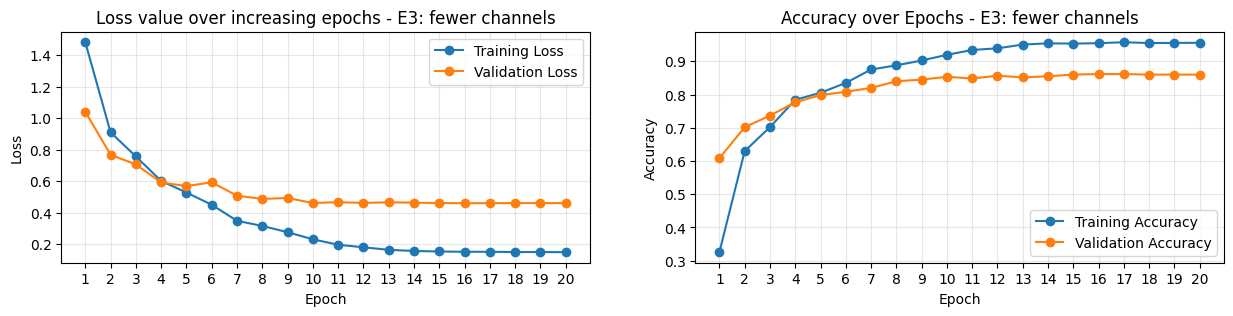

In [30]:
# E3: fewer channels (20, 30, 40) -> flatten = 40*16*16
def get_model_E3():
    model = nn.Sequential(
        nn.Conv2d(3, 20, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(20, 30, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Conv2d(30, 40, 3, padding=1),   # 32x32
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 16x16

        nn.Flatten(),
        nn.Linear(40*16*16, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E3 = run_experiment("E3: fewer channels", get_model_E3)
plot_curves("E3: fewer channels")

##  E4

E4: more channels
Epoch [1/20] | Train Loss: 1.3880 | Train Accuracy: 38.04% | Val Loss: 0.9660 | Val Accuracy: 63.67%
Epoch [2/20] | Train Loss: 0.9010 | Train Accuracy: 63.79% | Val Loss: 0.7253 | Val Accuracy: 74.83%
Epoch [3/20] | Train Loss: 0.7126 | Train Accuracy: 74.21% | Val Loss: 0.6141 | Val Accuracy: 77.17%
Epoch [4/20] | Train Loss: 0.6045 | Train Accuracy: 77.50% | Val Loss: 0.7912 | Val Accuracy: 67.50%
Epoch [5/20] | Train Loss: 0.4675 | Train Accuracy: 82.38% | Val Loss: 0.5719 | Val Accuracy: 77.33%
Epoch [6/20] | Train Loss: 0.3786 | Train Accuracy: 86.67% | Val Loss: 0.5461 | Val Accuracy: 80.00%
Epoch [7/20] | Train Loss: 0.3359 | Train Accuracy: 87.12% | Val Loss: 0.4854 | Val Accuracy: 80.50%
Epoch [8/20] | Train Loss: 0.2737 | Train Accuracy: 90.04% | Val Loss: 0.5032 | Val Accuracy: 81.50%
Epoch [9/20] | Train Loss: 0.1945 | Train Accuracy: 92.92% | Val Loss: 0.4553 | Val Accuracy: 82.83%
Epoch [10/20] | Train Loss: 0.1596 | Train Accuracy: 94.42% | Val Loss: 0

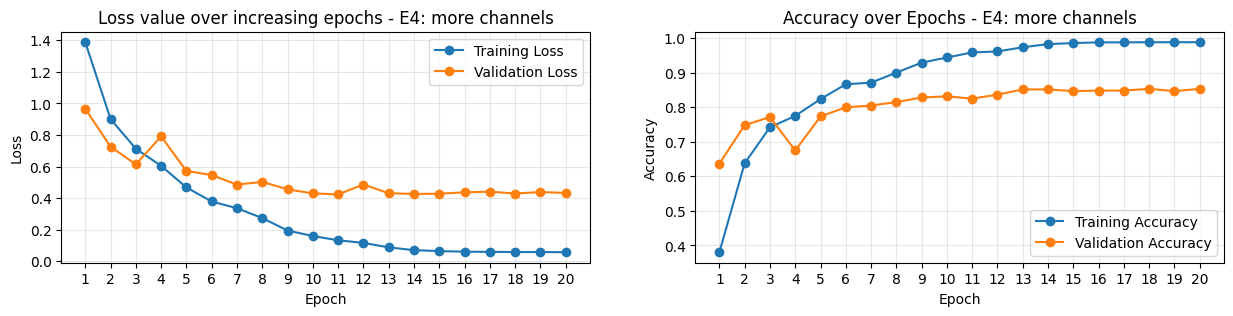

In [32]:
# E4: more channels (64, 96, 128) -> flatten = 128*16*16
def get_model_E4():
    model = nn.Sequential(
        nn.Conv2d(3, 64, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(64, 96, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Conv2d(96, 128, 3, padding=1),  # 32x32
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 16x16

        nn.Flatten(),
        nn.Linear(128*16*16, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E4 = run_experiment("E4: more channels", get_model_E4)
plot_curves("E4: more channels")

##  E5

E5: no hidden layer
Epoch [1/20] | Train Loss: 1.3056 | Train Accuracy: 43.33% | Val Loss: 0.8679 | Val Accuracy: 65.67%
Epoch [2/20] | Train Loss: 0.7651 | Train Accuracy: 70.58% | Val Loss: 0.6698 | Val Accuracy: 76.33%
Epoch [3/20] | Train Loss: 0.5984 | Train Accuracy: 78.79% | Val Loss: 0.5605 | Val Accuracy: 79.67%
Epoch [4/20] | Train Loss: 0.4943 | Train Accuracy: 82.58% | Val Loss: 0.5515 | Val Accuracy: 81.67%
Epoch [5/20] | Train Loss: 0.4529 | Train Accuracy: 84.17% | Val Loss: 0.5415 | Val Accuracy: 79.00%
Epoch [6/20] | Train Loss: 0.3829 | Train Accuracy: 86.58% | Val Loss: 0.4737 | Val Accuracy: 83.33%
Epoch [7/20] | Train Loss: 0.3456 | Train Accuracy: 87.88% | Val Loss: 0.4667 | Val Accuracy: 83.83%
Epoch [8/20] | Train Loss: 0.3043 | Train Accuracy: 88.75% | Val Loss: 0.4631 | Val Accuracy: 84.00%
Epoch [9/20] | Train Loss: 0.3224 | Train Accuracy: 88.42% | Val Loss: 0.5205 | Val Accuracy: 82.17%
Epoch [10/20] | Train Loss: 0.2358 | Train Accuracy: 91.96% | Val Loss:

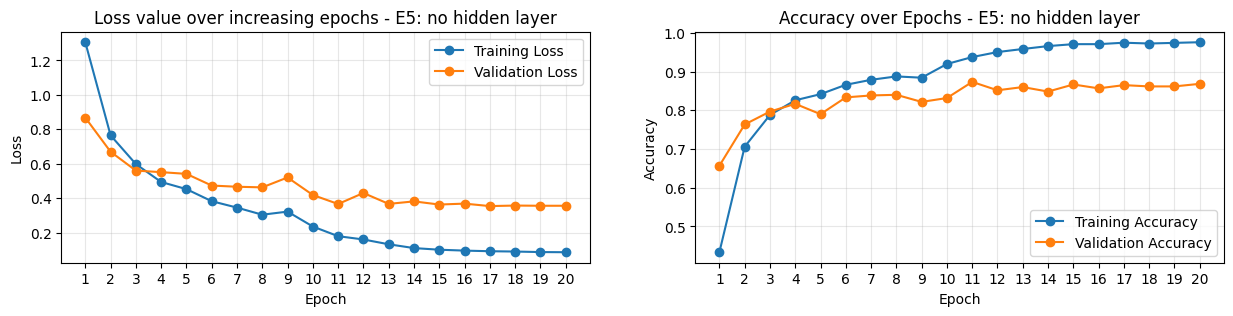

In [33]:
# E5: no hidden layer -> Flatten goes straight to the 5 outputs
def get_model_E5():
    model = nn.Sequential(
        nn.Conv2d(3, 40, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(40, 60, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Conv2d(60, 80, 3, padding=1),   # 32x32
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 16x16

        nn.Flatten(),
        nn.Linear(80*16*16, 5)             # no hidden layer
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E5 = run_experiment("E5: no hidden layer", get_model_E5)
plot_curves("E5: no hidden layer")

##  E6

E6: hidden 512
Epoch [1/20] | Train Loss: 1.2859 | Train Accuracy: 45.08% | Val Loss: 0.8805 | Val Accuracy: 66.00%
Epoch [2/20] | Train Loss: 0.7352 | Train Accuracy: 71.96% | Val Loss: 0.6565 | Val Accuracy: 74.83%
Epoch [3/20] | Train Loss: 0.5778 | Train Accuracy: 79.12% | Val Loss: 0.5845 | Val Accuracy: 79.33%
Epoch [4/20] | Train Loss: 0.4379 | Train Accuracy: 84.21% | Val Loss: 0.5645 | Val Accuracy: 80.00%
Epoch [5/20] | Train Loss: 0.3499 | Train Accuracy: 87.42% | Val Loss: 0.5214 | Val Accuracy: 83.17%
Epoch [6/20] | Train Loss: 0.3054 | Train Accuracy: 88.46% | Val Loss: 0.4894 | Val Accuracy: 82.33%
Epoch [7/20] | Train Loss: 0.2466 | Train Accuracy: 91.12% | Val Loss: 0.4775 | Val Accuracy: 82.67%
Epoch [8/20] | Train Loss: 0.1848 | Train Accuracy: 92.83% | Val Loss: 0.4701 | Val Accuracy: 84.00%
Epoch [9/20] | Train Loss: 0.1661 | Train Accuracy: 94.04% | Val Loss: 0.6965 | Val Accuracy: 77.00%
Epoch [10/20] | Train Loss: 0.1066 | Train Accuracy: 96.46% | Val Loss: 0.48

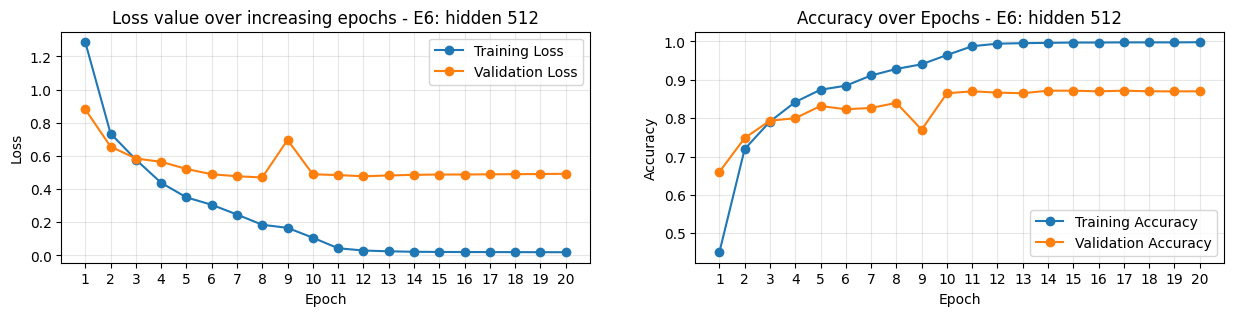

In [35]:
# E6: bigger hidden layer (512 neurons instead of 256)
def get_model_E6():
    model = nn.Sequential(
        nn.Conv2d(3, 40, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(40, 60, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Conv2d(60, 80, 3, padding=1),   # 32x32
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 16x16

        nn.Flatten(),
        nn.Linear(80*16*16, 512),
        nn.ReLU(),
        nn.Linear(512, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E6 = run_experiment("E6: hidden 512", get_model_E6)
plot_curves("E6: hidden 512")

##  E7

E7: two hidden layers
Epoch [1/20] | Train Loss: 1.2274 | Train Accuracy: 47.75% | Val Loss: 0.7398 | Val Accuracy: 71.33%
Epoch [2/20] | Train Loss: 0.7615 | Train Accuracy: 70.42% | Val Loss: 0.6926 | Val Accuracy: 76.33%
Epoch [3/20] | Train Loss: 0.5682 | Train Accuracy: 79.46% | Val Loss: 0.5976 | Val Accuracy: 77.67%
Epoch [4/20] | Train Loss: 0.4535 | Train Accuracy: 83.29% | Val Loss: 0.5744 | Val Accuracy: 79.00%
Epoch [5/20] | Train Loss: 0.3921 | Train Accuracy: 86.33% | Val Loss: 0.4544 | Val Accuracy: 84.50%
Epoch [6/20] | Train Loss: 0.2997 | Train Accuracy: 89.46% | Val Loss: 0.3875 | Val Accuracy: 86.67%
Epoch [7/20] | Train Loss: 0.2856 | Train Accuracy: 89.83% | Val Loss: 0.4730 | Val Accuracy: 83.50%
Epoch [8/20] | Train Loss: 0.1828 | Train Accuracy: 93.46% | Val Loss: 0.4787 | Val Accuracy: 84.67%
Epoch [9/20] | Train Loss: 0.1408 | Train Accuracy: 94.67% | Val Loss: 0.4169 | Val Accuracy: 85.33%
Epoch [10/20] | Train Loss: 0.1129 | Train Accuracy: 96.04% | Val Los

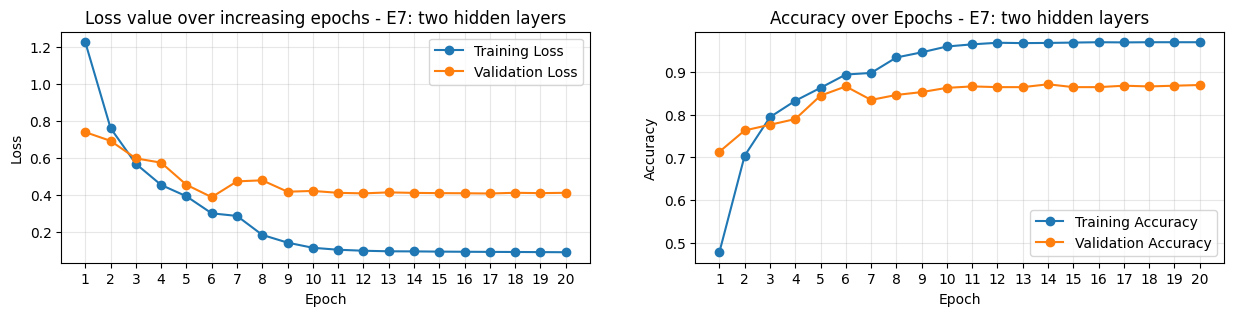

In [38]:
# E7: two hidden layers (256 -> 128)
def get_model_E7():
    model = nn.Sequential(
        nn.Conv2d(3, 40, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(40, 60, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Conv2d(60, 80, 3, padding=1),   # 32x32
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 16x16

        nn.Flatten(),
        nn.Linear(80*16*16, 256),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E7 = run_experiment("E7: two hidden layers", get_model_E7)
plot_curves("E7: two hidden layers")

## E8

E8: 4 conv + dropout
Epoch [1/20] | Train Loss: 1.5052 | Train Accuracy: 31.17% | Val Loss: 1.4040 | Val Accuracy: 37.17%
Epoch [2/20] | Train Loss: 0.9467 | Train Accuracy: 63.75% | Val Loss: 0.8526 | Val Accuracy: 71.17%
Epoch [3/20] | Train Loss: 0.6264 | Train Accuracy: 76.83% | Val Loss: 0.5826 | Val Accuracy: 77.33%
Epoch [4/20] | Train Loss: 0.4861 | Train Accuracy: 82.67% | Val Loss: 0.5037 | Val Accuracy: 81.50%
Epoch [5/20] | Train Loss: 0.3995 | Train Accuracy: 85.79% | Val Loss: 0.4289 | Val Accuracy: 84.50%
Epoch [6/20] | Train Loss: 0.3458 | Train Accuracy: 86.88% | Val Loss: 0.3921 | Val Accuracy: 85.17%
Epoch [7/20] | Train Loss: 0.2865 | Train Accuracy: 89.33% | Val Loss: 0.3434 | Val Accuracy: 87.33%
Epoch [8/20] | Train Loss: 0.2243 | Train Accuracy: 91.75% | Val Loss: 0.3635 | Val Accuracy: 87.33%
Epoch [9/20] | Train Loss: 0.1472 | Train Accuracy: 94.42% | Val Loss: 0.4097 | Val Accuracy: 85.83%
Epoch [10/20] | Train Loss: 0.1198 | Train Accuracy: 95.33% | Val Loss

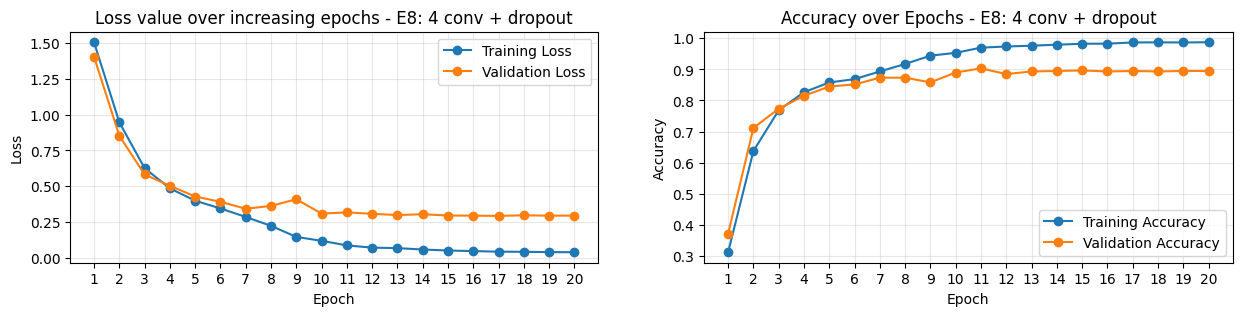

In [60]:
def get_model_E8():
    model = nn.Sequential(
        nn.Conv2d(3, 40, 3, padding=1),    # 128x128
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 64x64

        nn.Conv2d(40, 60, 3, padding=1),   # 64x64
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 32x32

        nn.Conv2d(60, 80, 3, padding=1),   # 32x32
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 16x16

        nn.Conv2d(80, 100, 3, padding=1),  # 16x16
        nn.ReLU(),
        nn.MaxPool2d(2),                   # 8x8

        nn.Flatten(),
        nn.Dropout(0.5),    
        nn.Linear(100*8*8, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model_E2 = run_experiment("E8: 4 conv + dropout", get_model_E2)
plot_curves("E8: 4 conv + dropout")

## 10. Compare all experiments


In [61]:
import pandas as pd

results_df = pd.DataFrame(results)

# Best (lowest) validation loss of each experiment, and the epoch where it happened
results_df["Best val loss"] = results_df["Experiment"].map(lambda n: min(histories[n]["val_losses"]))
results_df["Best loss epoch"] = results_df["Experiment"].map(lambda n: int(np.argmin(histories[n]["val_losses"])) + 1)

results_df[["Train acc", "Val acc", "Gap (train - val)", "Best val loss"]] = results_df[["Train acc", "Val acc", "Gap (train - val)", "Best val loss"]].round(3)
results_df

,Experiment,Parameters,Train acc,Val acc,Gap (train - val),Time (s),Best val loss,Best loss epoch
0,E1: 2 conv layers,15752961,0.993,0.828,0.165,42,0.596,7
1,E1: 2 conv layers,15752961,1.000,0.795,0.205,42,0.596,7
2,E2: 4 conv layers,1778101,0.998,0.915,0.083,42,0.319,13
3,E3: fewer channels,2639811,0.979,0.860,0.119,25,0.459,16
4,E3: fewer channels,2639811,0.956,0.860,0.096,25,0.459,16
5,E4: more channels,8558053,0.988,0.853,0.135,94,0.424,11
6,E5: no hidden layer,168465,0.976,0.868,0.108,38,0.354,17
7,E6: hidden 512,10554897,0.998,0.870,0.128,44,0.470,8
8,E7: two hidden layers,5342737,0.964,0.872,0.092,41,0.387,6
9,E7: two hidden layers,5342737,0.970,0.870,0.100,41,0.387,6


## 11. Validation Accuracy 

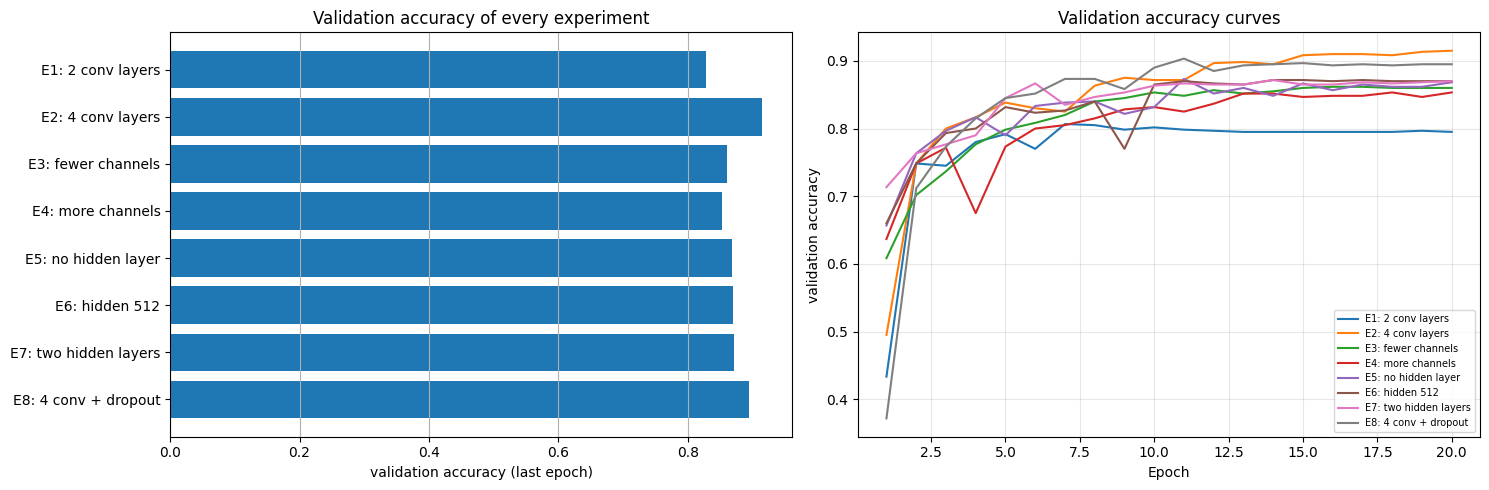

In [62]:
plt.figure(figsize=(15, 5))

# Left: final validation accuracy of every experiment
plt.subplot(1, 2, 1)
plt.barh(results_df["Experiment"], results_df["Val acc"])
plt.gca().invert_yaxis()
plt.xlabel("validation accuracy (last epoch)")
plt.title("Validation accuracy of every experiment")
plt.grid(True, axis="x")

# Right: validation accuracy over the epochs
plt.subplot(1, 2, 2)
for name, h in histories.items():
    plt.plot(np.arange(epoch_number) + 1, h["val_accuracies"], label=name)
plt.xlabel("Epoch")
plt.ylabel("validation accuracy")
plt.title("Validation accuracy curves")
plt.legend(fontsize=7)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Best model: confusion matrix and report

Best experiment (highest validation accuracy): E2: 4 conv layers
Validation accuracy: 0.915


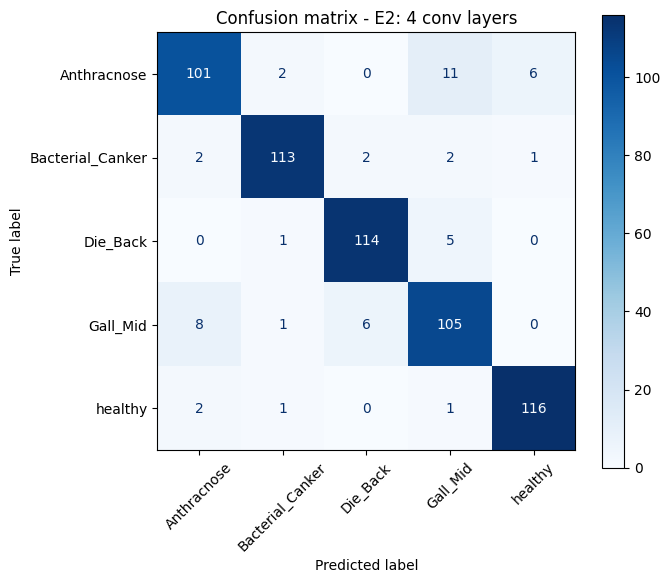

                  precision    recall  f1-score   support

     Anthracnose       0.89      0.84      0.87       120
Bacterial_Canker       0.96      0.94      0.95       120
        Die_Back       0.93      0.95      0.94       120
        Gall_Mid       0.85      0.88      0.86       120
         healthy       0.94      0.97      0.95       120

        accuracy                           0.92       600
       macro avg       0.92      0.92      0.91       600
    weighted avg       0.92      0.92      0.91       600



In [63]:
@torch.no_grad()
def get_predictions(model, data_loader):
    model.eval()
    all_pred, all_true = [], []
    for x, y in data_loader:
        prediction = model(x.to(device)).argmax(-1)
        all_pred.extend(prediction.cpu().tolist())
        all_true.extend(y.cpu().tolist())
    return np.array(all_pred), np.array(all_true)


best_name = results_df.loc[results_df["Val acc"].idxmax(), "Experiment"]
best_model = trained_models[best_name]
print("Best experiment (highest validation accuracy):", best_name)

y_pred, y_true = get_predictions(best_model, val_dl)
print(f"Validation accuracy: {(y_pred == y_true).mean():.3f}")

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("Confusion matrix - " + best_name)
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

### Test one validation image

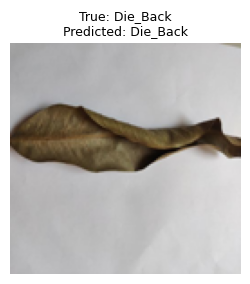

In [52]:
ix = np.random.randint(0, len(val_images))
img = val_images[ix] / 255.0
img = torch.tensor(img).float().permute(2, 0, 1).unsqueeze(0).to(device)

model_E0.eval()
with torch.no_grad():
    np_output = model_E0(img).cpu().numpy()
pred = np.exp(np_output) / np.sum(np.exp(np_output))     # scores -> probabilities

plt.figure(figsize=(3, 3))
plt.imshow(img.squeeze(0).permute(1, 2, 0).cpu().numpy())
plt.title("True: " + class_names[val_targets[ix]] + "\nPredicted: " + class_names[pred[0].argmax()], fontsize=9)
plt.axis("off")
plt.show()